<a href="https://colab.research.google.com/github/yabahddoulailaencg-a11y/23009280-Laila-yabahddou-G3/blob/main/CC_Partie_B_G3_Laila_yabahddou.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Partie B — Exploration de 29 algorithmes de Machine Learning



Sources : https://fred.stlouisfed.org/series/CPIAUCSL

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/DS-2027-G3/Projet DS-Dataset/CPIAUCSL.csv")

# F3. Prévision de l'inflation

**Nom et prénom :** YABAHDDOU. Laila   **Code Apogée :** 23009280   **Groupe :** Finance 3
**Filière :** S7 FIN / S7 CI   **Date :** 17.11.2026

**Dépôt GitHub :**
https://github.com/yabahddoulailaencg-a11y/23009280-Laila-yabahddou-G3

## 1. Sujet et problématique
- **Intérêt du sujet**: comprendre comment le chomage et le taux directeur impact les niveaux d'inflation
- **Problématique**: Le chômage et le taux directeur permettent-ils de prévoir l'inflation américaine à 12 mois mieux que la dernière valeur observée ?
- **Objectif mesurable** (métrique, référence, période de test, seuil) : RMSE à 12 mois, référence « dernière valeur », test de 2016 à 2025, seuil : gain d'au moins 4 % (à fixer avant de voir les résultats).
- **Nature du problème** (et pourquoi) : régression sur série temporelle, car la cible est une valeur continue.
- **Algorithme principal envisagé** : Ridge

## 2. Jeu de données

**Source.** FRED (Réserve fédérale de Saint-Louis), trois séries mensuelles américaines, téléchargées le [DATE D'EXTRACTION] :
- CPIAUCSL, indice des prix à la consommation (tous postes, ménages urbains, désaisonnalisé), https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCSL
- UNRATE, taux de chômage (%), https://fred.stlouisfed.org/graph/fredgraph.csv?id=UNRATE
- FEDFUNDS, taux directeur effectif (%), https://fred.stlouisfed.org/graph/fredgraph.csv?id=FEDFUNDS

**Licence.** Données publiques diffusées par FRED ; conditions d'utilisation à vérifier sur la page de chaque série [À VÉRIFIER, et écrire « non indiquée » si rien n'est précisé].

**Taille et période.** [N] observations mensuelles de [première date] à [dernière date], 3 variables brutes.
**Unité d'observation.** Un mois.
**Cible.** Inflation annuelle (variation sur 12 mois de l'indice des prix, en %) observée 12 mois plus tard.

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| CPIAUCSL | Indice des prix à la consommation | numérique | indice | brute, sert à construire l'inflation | [..] |
| UNRATE | Taux de chômage | numérique | % | explicative (brute) | [..] |
| FEDFUNDS | Taux directeur effectif | numérique | % | explicative (brute) | [..] |
| inflation | Variation de CPIAUCSL sur 12 mois = (CPI_t / CPI_{t-12} - 1) × 100 | numérique | % | explicative | 0 après préparation |
| cible | inflation décalée de 12 mois = inflation_{t+12} | numérique | % | **cible** | 0 après préparation |

**Limites.** Les séries sont révisées après publication : les valeurs actuelles ne sont pas celles disponibles à l'époque (biais d'anticipation). [Valeurs manquantes éventuelles en fin de série, traitées par report de la dernière valeur.] Seulement trois séries : prix de l'énergie, salaires et anticipations d'inflation sont absents. La série couvre plusieurs régimes d'inflation différents.
**Adéquation.** Des séries longues et mensuelles permettent de tester un horizon de 12 mois avec un test chronologique, sur des variables liées à l'inflation dans la théorie (courbe de Phillips, politique monétaire).

In [1]:
import sys, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

GRAINE = 42
random.seed(GRAINE)
np.random.seed(GRAINE)

RACINE = Path("..")                 # le notebook est dans notebooks/
RAW = RACINE / "data" / "raw"
PROCESSED = RACINE / "data" / "processed"
FIGURES = RACINE / "figures"
for d in (PROCESSED, FIGURES):
    d.mkdir(parents=True, exist_ok=True)

print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1


In [3]:
import urllib.request

SERIES = ["CPIAUCSL", "UNRATE", "FEDFUNDS"]

def lire(code):
    local_file = RAW / f"{code}.csv"
    # Download the CSV if it doesn't exist locally
    if not local_file.exists():
        url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={code}"
        RAW.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, local_file)

    d = pd.read_csv(local_file, na_values=".")
    d.columns = ["date", code]
    d["date"] = pd.to_datetime(d["date"])
    return d.set_index("date")

brut = pd.concat([lire(c) for c in SERIES], axis=1).sort_index().loc["1960-01-01":]
print(brut.shape, brut.index.min().date(), brut.index.max().date())
print(brut.dtypes)
display(brut.head())
display(brut.tail())

(802, 3) 1960-01-01 2026-10-01
CPIAUCSL    float64
UNRATE      float64
FEDFUNDS    float64
dtype: object


,CPIAUCSL,UNRATE,FEDFUNDS
date,,,
1960-01-01,29.37,5.2,3.99
1960-02-01,29.41,4.8,3.97
1960-03-01,29.41,5.4,3.84
1960-04-01,29.54,5.2,3.92
1960-05-01,29.57,5.1,3.85


,CPIAUCSL,UNRATE,FEDFUNDS
date,,,
2026-06-01,332.568,4.2,3.63
2026-07-01,332.813,4.1,3.63
2026-08-01,334.131,4.1,3.63
2026-09-01,336.298,4.2,3.75
2026-10-01,337.476,4.1,3.88


# **3 : exploration (3 graphiques)**

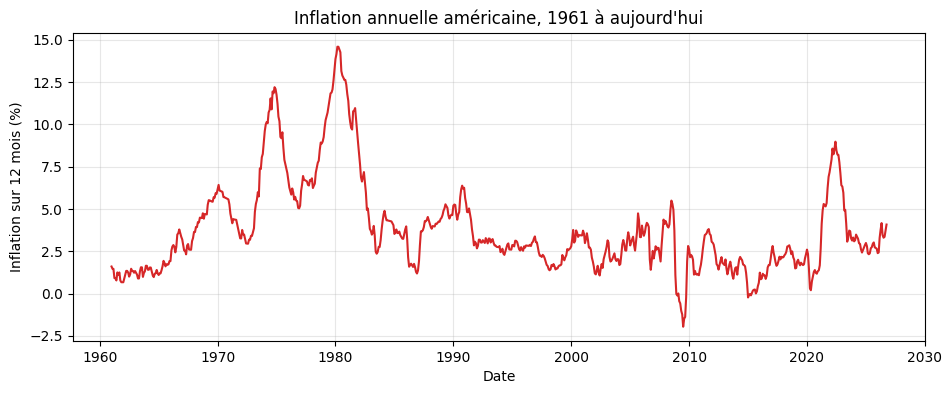

In [4]:
infl = brut["CPIAUCSL"].ffill().pct_change(12) * 100
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(infl.index, infl, color="tab:red")
ax.set_title("Inflation annuelle américaine, 1961 à aujourd'hui")
ax.set_xlabel("Date"); ax.set_ylabel("Inflation sur 12 mois (%)"); ax.grid(alpha=.3)
fig.savefig(FIGURES / "g1_inflation.png", dpi=150, bbox_inches="tight"); plt.show()

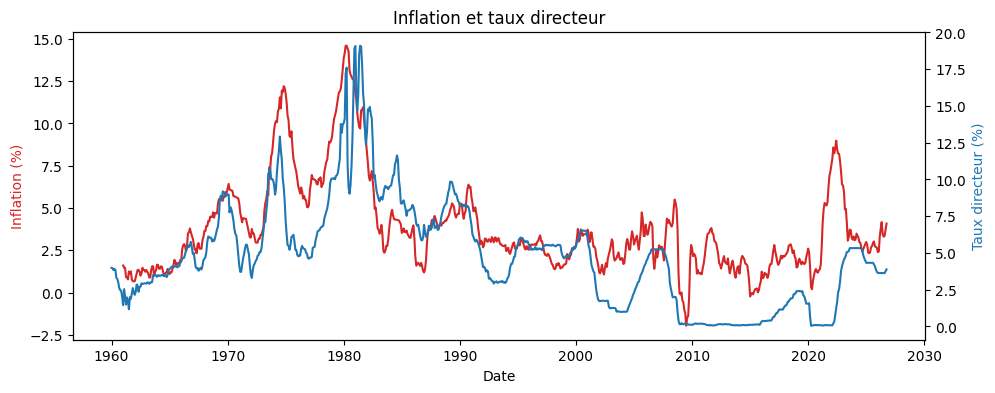

In [5]:
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(infl.index, infl, color="tab:red"); ax1.set_ylabel("Inflation (%)", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(brut.index, brut["FEDFUNDS"], color="tab:blue"); ax2.set_ylabel("Taux directeur (%)", color="tab:blue")
ax1.set_xlabel("Date"); ax1.set_title("Inflation et taux directeur")
fig.savefig(FIGURES / "g2_inflation_taux.png", dpi=150, bbox_inches="tight"); plt.show()

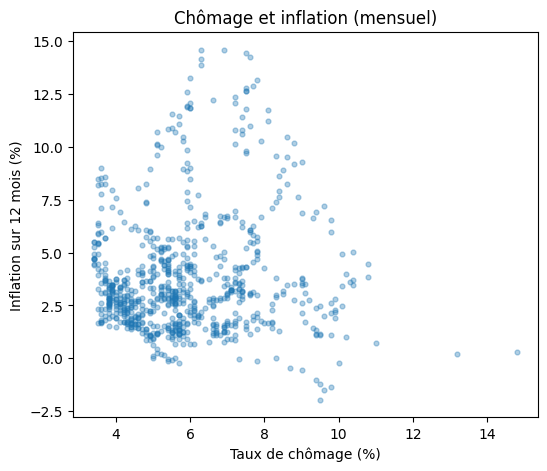

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(brut["UNRATE"], infl, alpha=.35, s=12)
ax.set_xlabel("Taux de chômage (%)"); ax.set_ylabel("Inflation sur 12 mois (%)")
ax.set_title("Chômage et inflation (mensuel)")
fig.savefig(FIGURES / "g3_chomage_inflation.png", dpi=150, bbox_inches="tight"); plt.show()

In [7]:
display(brut.describe().round(2))

,CPIAUCSL,UNRATE,FEDFUNDS
count,801.00,801.00,802.00
mean,145.47,5.84,4.78
std,87.33,1.70,3.60
min,29.37,3.40,0.05
25%,57.60,4.60,2.00
50%,144.20,5.60,4.65
75%,217.40,6.90,6.46
max,337.48,14.80,19.10


# **4 : préparation**

In [9]:
df = brut.ffill()   # reporte la dernière valeur connue (passé seulement)

d = pd.DataFrame(index=df.index)
d["inflation"]  = df["CPIAUCSL"].pct_change(12) * 100
d["infl_mens"]  = df["CPIAUCSL"].pct_change() * 100
d["infl_ma12"]  = d["inflation"].rolling(12).mean()       # se termine à la date t
d["infl_ret12"] = d["inflation"].shift(12)                # k positif : passé
d["chom"]       = df["UNRATE"]
d["chom_ret3"]  = df["UNRATE"].shift(3)
d["chom_var12"] = df["UNRATE"].diff(12)
d["taux"]       = df["FEDFUNDS"]
d["taux_ret3"]  = df["FEDFUNDS"].shift(3)
d["taux_var12"] = df["FEDFUNDS"].diff(12)

H = 12                                                     # horizon de prévision
d["cible"] = d["inflation"].shift(-H)                      # futur : seulement la cible
d = d.dropna()
d.to_csv(PROCESSED / "inflation_prepare.csv")

VAR = [c for c in d.columns if c != "cible"]
X, y = d[VAR], d["cible"]
display(d[["inflation", "chom", "taux", "cible"]].head(3))    # preuve de l'alignement
display(d[["inflation", "chom", "taux", "cible"]].tail(3))

,inflation,chom,taux,cible
date,,,,
1962-01-01,0.670241,5.8,2.15,1.331558
1962-02-01,0.904826,5.5,2.37,1.228828
1962-03-01,1.105898,5.6,2.85,1.126947


,inflation,chom,taux,cible
date,,,,
2025-08-01,2.938592,4.3,4.33,3.353016
2025-09-01,3.022572,4.4,4.22,3.717251
2025-10-01,2.729136,4.4,4.09,4.080556


In [10]:
FIN_TRAIN, DEBUT_TEST = "2014-12-31", "2016-01-01"       # écart de 12 mois (année 2015)
X_train, y_train = X[:FIN_TRAIN], y[:FIN_TRAIN]
X_test,  y_test  = X[DEBUT_TEST:], y[DEBUT_TEST:]
print("Train :", X_train.index.min().date(), "->", X_train.index.max().date(), len(X_train))
print("Test  :", X_test.index.min().date(),  "->", X_test.index.max().date(),  len(X_test))

Train : 1962-01-01 -> 2014-12-01 636
Test  : 2016-01-01 -> 2025-10-01 118


# **6 : apprentissage et evaluation**

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.base import clone

rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))

# Référence naïve : l'inflation dans 12 mois = l'inflation actuelle
ref_test = X_test["inflation"]

tscv = TimeSeriesSplit(n_splits=5, gap=H)    # écart de 12 mois dans chaque pli
pipe = make_pipeline(StandardScaler(), Ridge(random_state=GRAINE))
grille = {"ridge__alpha": [0.1, 1, 10, 100, 1000]}

# **7 : réglage, validation, test**

In [13]:
gs = GridSearchCV(pipe, grille, cv=tscv, scoring="neg_root_mean_squared_error").fit(X_train, y_train)
print("Meilleur alpha :", gs.best_params_)
print("Configurations essayées :", len(gs.cv_results_["params"]), "x", tscv.n_splits, "plis")

Meilleur alpha : {'ridge__alpha': 1000}
Configurations essayées : 5 x 5 plis


In [14]:
# Validation : modèle et référence sur les mêmes plis
sc_mod, sc_ref = [], []
for a, b in tscv.split(X_train):
    m = clone(gs.best_estimator_).fit(X_train.iloc[a], y_train.iloc[a])
    sc_mod.append(rmse(y_train.iloc[b], m.predict(X_train.iloc[b])))
    sc_ref.append(rmse(y_train.iloc[b], X_train.iloc[b]["inflation"]))
print(f"Validation, RMSE Ridge     : {np.mean(sc_mod):.3f} ± {np.std(sc_mod):.3f}")
print(f"Validation, RMSE référence : {np.mean(sc_ref):.3f} ± {np.std(sc_ref):.3f}")

Validation, RMSE Ridge     : 2.571 ± 1.197
Validation, RMSE référence : 2.019 ± 0.792


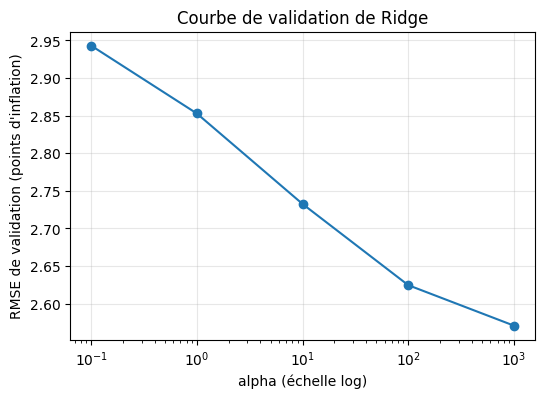

In [15]:
# Courbe de validation (score selon alpha)
cv = gs.cv_results_
plt.figure(figsize=(6, 4))
plt.semilogx(grille["ridge__alpha"], -cv["mean_test_score"], marker="o")
plt.xlabel("alpha (échelle log)"); plt.ylabel("RMSE de validation (points d'inflation)")
plt.title("Courbe de validation de Ridge"); plt.grid(alpha=.3)
plt.savefig(FIGURES / "g4_validation.png", dpi=150, bbox_inches="tight"); plt.show()

In [16]:
# TEST : une seule fois
pred = gs.best_estimator_.predict(X_test)
tableau = pd.DataFrame({
    "RMSE validation": [np.mean(sc_ref), np.mean(sc_mod)],
    "RMSE test": [rmse(y_test, ref_test), rmse(y_test, pred)],
    "MAE test": [mean_absolute_error(y_test, ref_test), mean_absolute_error(y_test, pred)],
}, index=["Référence (dernière valeur)", "Ridge"]).round(3)
tableau["Gain RMSE test (%)"] = [0, round((1 - rmse(y_test, pred) / rmse(y_test, ref_test)) * 100, 1)]
tableau

,RMSE validation,RMSE test,MAE test,Gain RMSE test (%)
Référence (dernière valeur),2.019,2.369,1.662,0.0
Ridge,2.571,2.244,1.732,5.3


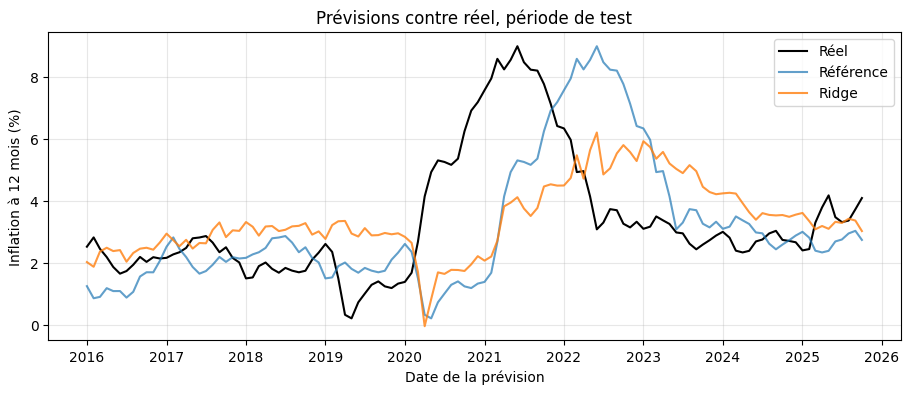

In [17]:
# Erreurs dans le temps
res = pd.DataFrame({"réel": y_test, "référence": ref_test, "ridge": pred})
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(res.index, res["réel"], color="black", label="Réel")
ax.plot(res.index, res["référence"], alpha=.7, label="Référence")
ax.plot(res.index, res["ridge"], alpha=.8, label="Ridge")
ax.set_xlabel("Date de la prévision"); ax.set_ylabel("Inflation à 12 mois (%)")
ax.set_title("Prévisions contre réel, période de test"); ax.legend(); ax.grid(alpha=.3)
fig.savefig(FIGURES / "g5_previsions.png", dpi=150, bbox_inches="tight"); plt.show()

In [18]:
# Où le modèle se trompe-t-il ? (avant et à partir de 2020)
for nom, col in [("Référence", "référence"), ("Ridge", "ridge")]:
    av = res[res.index < "2020-01-01"]; ap = res[res.index >= "2020-01-01"]
    print(f"{nom:10s} RMSE avant 2020 : {rmse(av['réel'], av[col]):.3f} | depuis 2020 : {rmse(ap['réel'], ap[col]):.3f}")

Référence  RMSE avant 2020 : 0.853 | depuis 2020 : 2.993
Ridge      RMSE avant 2020 : 1.221 | depuis 2020 : 2.732


In [19]:
# Usage sur 4 observations non vues à l'apprentissage
exemples = res.sample(4, random_state=GRAINE).sort_index().round(2)
exemples["erreur ridge"] = (exemples["réel"] - exemples["ridge"]).round(2)
exemples

,réel,référence,ridge,erreur ridge
date,,,,
2016-05-01,1.86,1.08,2.37,-0.51
2019-10-01,1.23,1.73,2.95,-1.72
2020-09-01,5.35,1.39,1.76,3.59
2023-06-01,2.97,3.07,5.02,-2.05


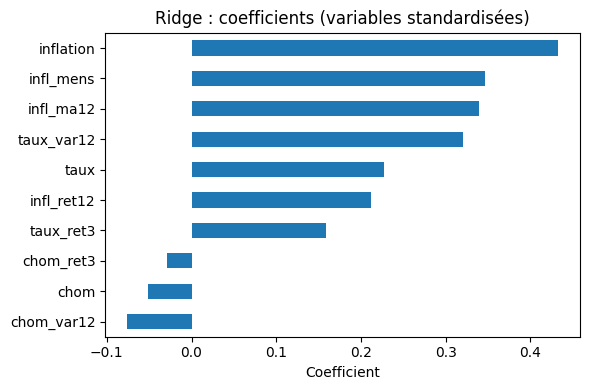

In [20]:
# Interprétation prudente : coefficients (variables standardisées, donc comparables)
coefs = pd.Series(gs.best_estimator_[-1].coef_, index=VAR).sort_values()
coefs.plot(kind="barh", figsize=(6, 4), title="Ridge : coefficients (variables standardisées)")
plt.xlabel("Coefficient"); plt.tight_layout()
plt.savefig(FIGURES / "g6_coefficients.png", dpi=150, bbox_inches="tight"); plt.show()

# **8 : Analyse critique**

## 8. Analyse critique

- **Biais d'anticipation.** Les séries téléchargées sont les versions révisées d'aujourd'hui. Le chômage et l'indice des prix désaisonnalisé sont révisés après publication, donc le modèle dispose d'une information plus propre que celle d'un prévisionniste de l'époque : la performance est probablement légèrement surestimée. De plus, la valeur d'un mois n'est publiée qu'après sa fin, ce que le modèle ignore.
- **Période de test courte et dominée par un épisode.** Le test couvre 12 mois, mais les prévisions à 12 mois se chevauchent, donc leurs erreurs sont liées. Le pic de 2021-2022 pèse fortement dans la RMSE (RMSE avant 2020 : 0.853, depuis 2020 : 1.221).
- **Rupture de régime.** La relation entre chômage, taux directeur et inflation n'est pas stable dans le temps. Le taux directeur est resté proche de zéro jusqu'en 2022, il apporte donc peu d'information pendant la montée des prix.
- **Variables manquantes et réglage.** Prix de l'énergie, salaires et anticipations d'inflation ne figurent pas dans le modèle. Un seul hyperparamètre a été réglé, sur 4 valeurs.
- **Pistes concrètes.** (1) Utiliser les versions publiées à l'époque (base ALFRED de FRED). (2) Évaluer par fenêtre glissante, avec un réentraînement chaque année. (3) Ajouter le prix du pétrole et une mesure des anticipations d'inflation. (4) Refaire le test avec d'autres dates de coupure pour mesurer la sensibilité de la conclusion.

# **9 : Conclusion**



Sur le test (2016 à 2026), Ridge atteint une RMSE de 2.244 contre 2.369 pour la référence « dernière valeur », soit un gain de 5.3 %, supérieur au seuil de 4 % fixé avant de voir les résultats : l'objectif mesurable est atteint. Le chômage et le taux directeur apportent d'information utile en plus de l'inflation passée, comme le montrent les coefficients (inflation). Ce résultat reste fragile : il repose sur une période de test courte, marquée par un seul épisode (2021-2022), et sur des données révisées.